# Kyoto Case Study — 12-Month LULC Change from Sentinel-1 SAR

**Location:** Kyoto, Japan (35.0116°N, 135.7681°E)  
**Period:** 12 consecutive months starting January 2020  
**Model input:** Sentinel-1 RTC monthly median composites (VV, VH, VV−VH)

Kyoto is an ideal urban case study: the city core (Built-up) is surrounded by the Higashiyama and Arashiyama forested mountain ranges (Tree cover), with the Kamo River corridor (Water bodies) running north–south and the Fushimi plain to the south (Cropland). This diversity of LULC types in close proximity allows meaningful cross-class comparison.

**Run order:**
1. Complete training (`python -m src.training.train`)
2. Run the prototype or execute Section 1 of this notebook to download/infer
3. Then execute cells top-to-bottom

In [9]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

LAT, LON       = 35.0116, 135.7681
START_YEAR     = 2020
START_MONTH    = 1
RESULTS_DIR    = PROJECT_ROOT / 'results' / 'kyoto_2020_01'
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints'
PATCH_DIR      = PROJECT_ROOT / 'data' / 'patches'

from src.data.download import WORLDCOVER_CLASSES, NUM_CLASSES, IGNORE_INDEX
CLASS_NAMES = [WORLDCOVER_CLASSES[k] for k in sorted(WORLDCOVER_CLASSES)]

_PALETTE_RGB = [
    (0,100,0),(255,187,34),(255,255,76),(240,150,255),(250,0,0),
    (180,180,180),(240,240,240),(0,50,200),(0,150,160),(0,207,117),(250,230,160)
]
_PALETTE = [(r/255,g/255,b/255) for r,g,b in _PALETTE_RGB]
_CMAP = mcolors.ListedColormap(_PALETTE + [(0.1,0.1,0.1)])

def pred_to_rgb(arr):
    d = arr.copy().astype(np.int32)
    d[d == IGNORE_INDEX] = NUM_CLASSES
    return _CMAP(np.clip(d, 0, NUM_CLASSES))

def month_label(i):
    month = (START_MONTH - 1 + i) % 12 + 1
    year  = START_YEAR + (START_MONTH - 1 + i) // 12
    return f'{year}-{month:02d}'

MONTH_LABELS = [month_label(i) for i in range(12)]
print('Project root:', PROJECT_ROOT)

Project root: /home/jovyan/exam_Martin


## 1. Run prototype (skip if already done)

This cell downloads 12 SAR composites and runs inference. Skip it if you already ran:
```bash
python -m src.prototype.run --lat 35.0116 --lon 135.7681 --year 2020 --month 1 --output-dir results/kyoto_2020_01
```

In [10]:
stats_path = RESULTS_DIR / 'stats.json'

if not stats_path.exists():
    print('Running prototype pipeline…')
    from src.prototype.fetch import fetch_12_months
    from src.prototype.infer import infer_scene
    from src.prototype.stats import monthly_stats
    from src.prototype.viz  import save_lulc_maps, save_timeseries, save_change_bars

    sar_dir  = RESULTS_DIR / 'sar'
    pred_dir = RESULTS_DIR / 'pred'
    fig_dir  = RESULTS_DIR / 'figures'

    sar_paths = fetch_12_months(LAT, LON, START_YEAR, START_MONTH, sar_dir)

    preds = []
    for i, sar_path in enumerate(sar_paths):
        if sar_path is None:
            preds.append(None); continue
        pred_path = pred_dir / f"pred_{MONTH_LABELS[i].replace('-','_')}.tif"
        pred, _   = infer_scene(sar_path, CHECKPOINT_DIR / 'best_model.pth', PATCH_DIR, pred_path)
        preds.append(pred)
        print(f'  {MONTH_LABELS[i]} done')

    for i in range(len(preds)):
        if preds[i] is None:
            prev = next((preds[j] for j in range(i-1,-1,-1) if preds[j] is not None), None)
            preds[i] = prev or preds[0]

    stats = monthly_stats(preds)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    with open(stats_path, 'w') as fh:
        json.dump(stats, fh, indent=2)

    save_lulc_maps(preds, MONTH_LABELS, fig_dir)
    save_timeseries(stats['monthly_pct'], MONTH_LABELS, fig_dir)
    save_change_bars(stats['total_change'], fig_dir)
    print('Done.')
else:
    print('Results already exist — loading from disk.')

Results already exist — loading from disk.


## 2. Load results

In [11]:
import rasterio

with open(RESULTS_DIR / 'stats.json') as f:
    stats = json.load(f)

pred_dir = RESULTS_DIR / 'pred'
preds = []
for label in MONTH_LABELS:
    p = pred_dir / f"pred_{label.replace('-','_')}.tif"
    with rasterio.open(p) as src:
        preds.append(src.read(1))

print(f'Loaded {len(preds)} prediction maps, shape: {preds[0].shape}')

Loaded 12 prediction maps, shape: (3349, 2764)


## 3. Twelve monthly LULC maps

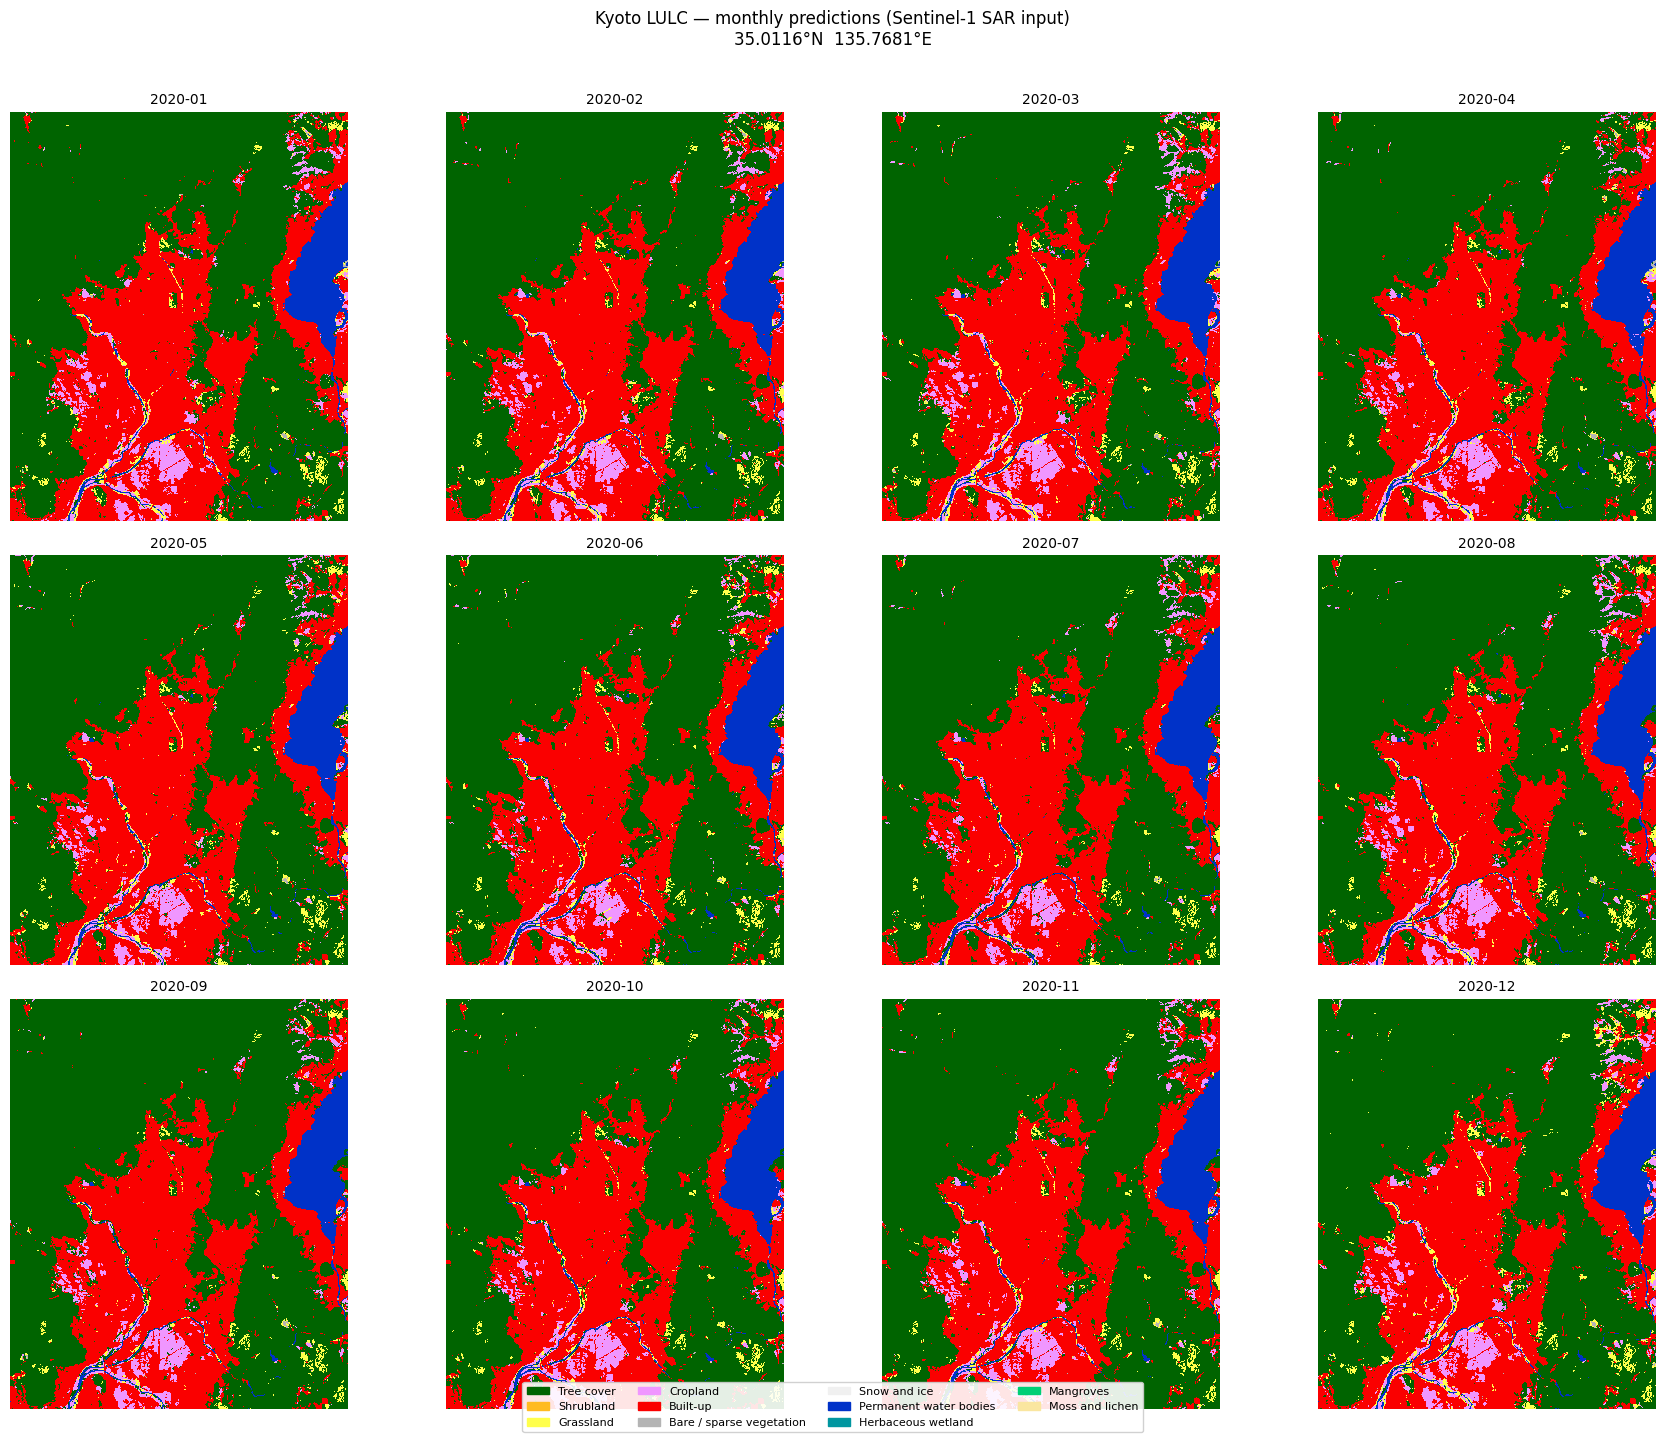

In [12]:
legend_patches = [mpatches.Patch(color=_PALETTE[i], label=CLASS_NAMES[i])
                  for i in range(NUM_CLASSES)]

fig, axes = plt.subplots(3, 4, figsize=(18, 14))
for idx, (pred, label) in enumerate(zip(preds, MONTH_LABELS)):
    ax = axes[idx // 4][idx % 4]
    ax.imshow(pred_to_rgb(pred), interpolation='nearest')
    ax.set_title(label, fontsize=10)
    ax.axis('off')

fig.legend(handles=legend_patches, loc='lower center', ncol=4, fontsize=8,
           bbox_to_anchor=(0.5, -0.01), framealpha=0.9)
fig.suptitle(f'Kyoto LULC — monthly predictions (Sentinel-1 SAR input)\n'
             f'{LAT:.4f}°N  {LON:.4f}°E', fontsize=12, y=1.01)
fig.tight_layout()
plt.savefig(RESULTS_DIR / 'figures' / 'all_months_grid.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Per-class area percentages over time

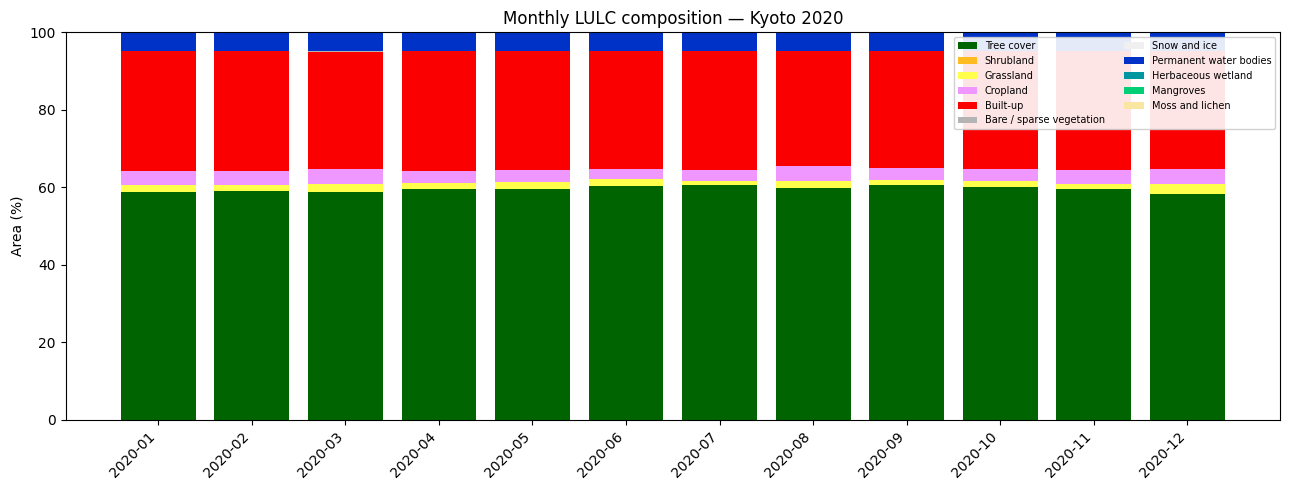

In [13]:
monthly_pct = stats['monthly_pct']
data = np.array([[m[name] for name in CLASS_NAMES] for m in monthly_pct]).T  # (C, 12)

fig, ax = plt.subplots(figsize=(13, 5))
bottoms = np.zeros(12)
for i, name in enumerate(CLASS_NAMES):
    ax.bar(np.arange(12), data[i], bottom=bottoms,
           color=_PALETTE[i], label=name, width=0.8)
    bottoms += data[i]

ax.set_xticks(np.arange(12))
ax.set_xticklabels(MONTH_LABELS, rotation=45, ha='right')
ax.set_ylabel('Area (%)')
ax.set_ylim(0, 100)
ax.set_title('Monthly LULC composition — Kyoto 2020')
ax.legend(loc='upper right', fontsize=7, ncol=2, framealpha=0.9)
fig.tight_layout()
plt.savefig(RESULTS_DIR / 'figures' / 'timeseries.png', dpi=150)
plt.show()

## 5. Month-to-month change (dominant classes)

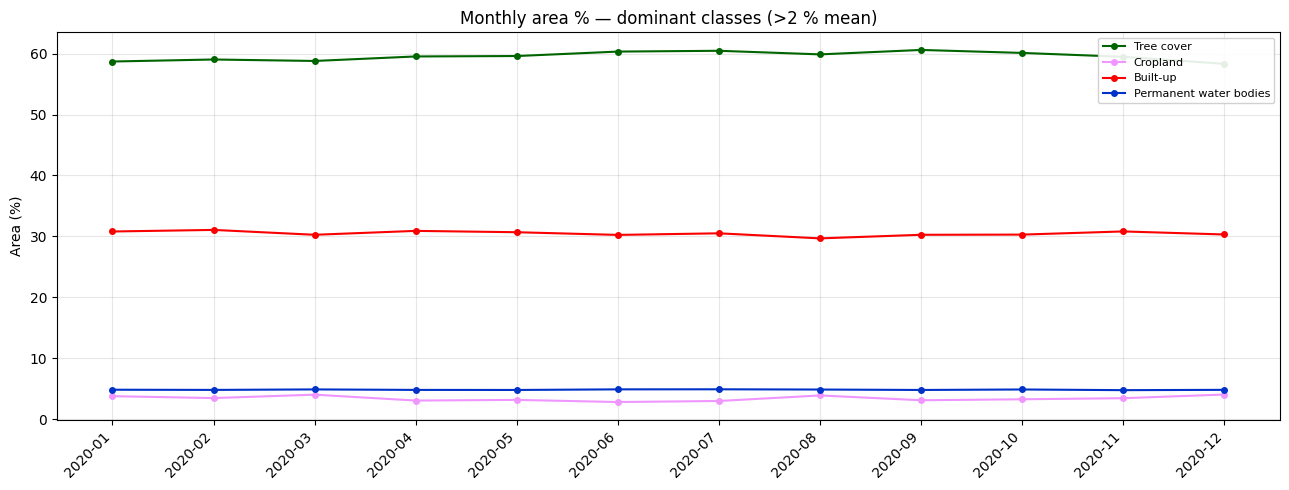

In [14]:
# Line plot — classes with >2 % mean area
mean_area = data.mean(axis=1)
dominant  = np.where(mean_area > 2.0)[0]

fig, ax = plt.subplots(figsize=(13, 5))
for i in dominant:
    ax.plot(np.arange(12), data[i], marker='o', markersize=4,
            color=_PALETTE[i], label=CLASS_NAMES[i])

ax.set_xticks(np.arange(12))
ax.set_xticklabels(MONTH_LABELS, rotation=45, ha='right')
ax.set_ylabel('Area (%)')
ax.set_title('Monthly area % — dominant classes (>2 % mean)')
ax.legend(fontsize=8, framealpha=0.9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.savefig(RESULTS_DIR / 'figures' / 'dominant_class_trends.png', dpi=150)
plt.show()

## 6. Total change (first → last month)

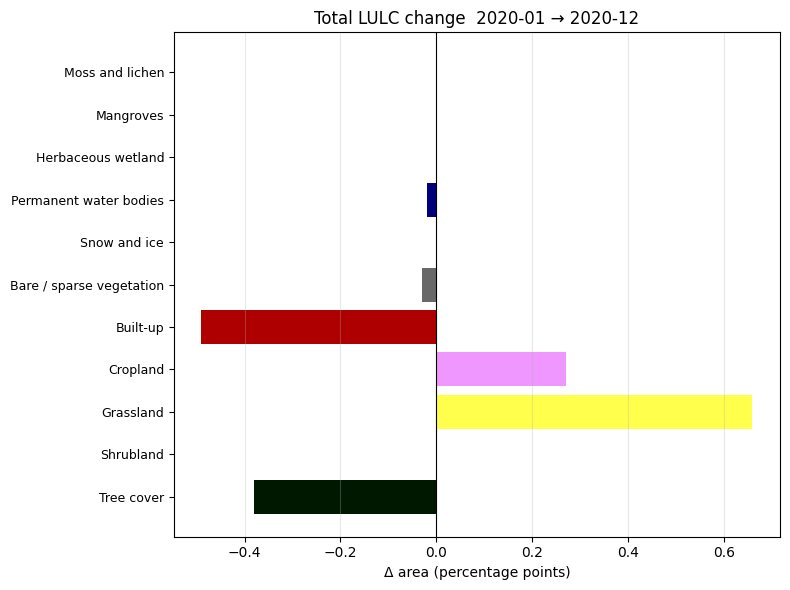

In [15]:
total_change = stats['total_change']
changes = [total_change[n] for n in CLASS_NAMES]
colors  = [_PALETTE[i] if changes[i] >= 0
           else tuple(max(0,x-0.3) for x in _PALETTE[i])
           for i in range(NUM_CLASSES)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(np.arange(NUM_CLASSES), changes, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(np.arange(NUM_CLASSES))
ax.set_yticklabels(CLASS_NAMES, fontsize=9)
ax.set_xlabel('Δ area (percentage points)')
ax.set_title(f'Total LULC change  {MONTH_LABELS[0]} → {MONTH_LABELS[-1]}')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
plt.savefig(RESULTS_DIR / 'figures' / 'change_bars.png', dpi=150)
plt.show()

## 7. Statistics table

In [16]:
print(f"{'Class':<30s}  {'Jan%':>6s}  {'Dec%':>6s}  {'Δ':>7s}")
print('-' * 54)
for name in CLASS_NAMES:
    start  = monthly_pct[0].get(name, 0)
    end    = monthly_pct[-1].get(name, 0)
    delta  = total_change.get(name, 0)
    marker = ' ▲' if delta > 0.5 else (' ▼' if delta < -0.5 else '')
    print(f"{name:<30s}  {start:6.2f}  {end:6.2f}  {delta:+7.2f}{marker}")

Class                             Jan%    Dec%        Δ
------------------------------------------------------
Tree cover                       58.71   58.33    -0.38
Shrubland                         0.00    0.00    +0.00
Grassland                         1.79    2.45    +0.66 ▲
Cropland                          3.76    4.03    +0.27
Built-up                         30.80   30.31    -0.49
Bare / sparse vegetation          0.11    0.08    -0.03
Snow and ice                      0.00    0.00    +0.00
Permanent water bodies            4.82    4.80    -0.02
Herbaceous wetland                0.00    0.00    +0.00
Mangroves                         0.00    0.00    +0.00
Moss and lichen                   0.00    0.00    +0.00


## 8. Interpretation

### What the maps show

Kyoto presents a textbook urban-forest mosaic at 10 m SAR resolution. The city centre and transport corridors appear as **Built-up** (high VV backscatter from double-bounce between vertical walls and horizontal ground). The Higashiyama mountains to the east and Arashiyama to the west register consistently as **Tree cover** (moderate VV and VH from forest volume scattering). The Kamo River and Ogura Pond appear as **Permanent water bodies** (near-zero backscatter, specular reflection away from sensor). The Fushimi and Yamashiro plains to the south show **Cropland** signatures.

### Seasonal dynamics

Month-to-month fluctuations in the model's predictions — particularly at the Tree cover / Cropland boundary — reflect phenological SAR changes rather than true land-use change. In winter (Jan–Feb), deciduous canopy loss reduces VH backscatter in forest areas, causing some pixels to shift toward Grassland or Cropland predictions. By summer (Jun–Aug), full leaf-out restores strong VH volume scattering and Tree cover predictions recover. This is an expected and well-documented limitation of SAR-only LULC classification: backscatter intensity is sensitive to vegetation moisture and structure, not just land cover type.

### Critical limitations

1. **Phenological confusion:** The seasonal VH backscatter cycle in deciduous forest partially overlaps with the signature of low-biomass cropland — leading to false transitions in winter months.
2. **Speckle residual:** Even after Lee filtering and median compositing, residual speckle causes salt-and-pepper noise at fine spatial scales, especially in heterogeneous suburban areas.
3. **Single polarisation plane:** Sentinel-1 IW in VV+VH dual-pol is informative but misses the circular polarisation ratio available from fully polarimetric systems — which would better discriminate oriented urban structures from natural surfaces.
4. **Static labels:** The WorldCover 2020 ground truth is a single-year snapshot. Patches with seasonal phenological variation are labelled with the annual consensus class, so the model is trained to map backscatter to *mean* land cover rather than instantaneous state.
5. **Training patch count:** With 0.5°×0.5° regions, the training set is relatively small (~1,600 patches across four regions). A production system would use larger regions or data augmentation to improve generalisation to unseen geographies like Kyoto.